# Difference in differences in differences

A retailer refurbished some stores fully and some lightly, and left a third group untouched. In every tier, some stores were treated and some were not, and the change is measured over the same two periods.

The question is not whether full refurbishment changed sales. That is the ordinary difference in differences for the full tier. The question is how much larger the treated-versus-control sales change was for full refurbishments than for lite ones.

Two shortcuts get that comparison wrong. One asks for a single regression coefficient that mixes all three tiers. The other subtracts the two tiers' standard errors and treats the result as the uncertainty of the comparison. The comparison below is the difference of two ordinary difference-in-differences, `DiD(full) - DiD(lite)`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

import pandas as pd
from sklearn.linear_model import LinearRegression

import causalpy as cp

# The formula already includes the intercept, so the scikit-learn model must not fit a second one.
MODEL = LinearRegression(fit_intercept=False)
FIG_WIDTH = 8
FIG_HEIGHT = 5
FORMULA = "y ~ 1 + group * post_treatment"
TREATED_POST = {"none": 3.0, "lite": 6.0, "full": 10.0}

## The three sales changes

Control sales rise by 1 in every tier. Treated sales rise by 3 where nothing was refurbished, by 6 for a lite refurbishment, and by 10 for a full one. Subtracting in words, the treated stores pulled ahead of control by 2, 5, and 9 sales units.

In [2]:
rows = []
for tier, treated_rise in TREATED_POST.items():
    for group, rise in ((0, 1.0), (1, treated_rise)):
        for time, post in ((0, 0), (1, 1)):
            rows.append(
                {
                    "unit": f"{tier}-g{group}",
                    "t": time,
                    "group": group,
                    "post_treatment": post,
                    "tier": tier,
                    "y": 0.0 if post == 0 else rise,
                }
            )
sales = pd.DataFrame(rows)
wide = sales.pivot_table(index=["tier", "group"], columns="post_treatment", values="y")
wide["change"] = wide[1] - wide[0]
wide = wide.reset_index()
wide["group"] = wide["group"].map({0: "control", 1: "treated"})
changes = (
    wide.pivot(index="tier", columns="group", values="change")
    .rename_axis(columns=None)
    .reindex(["none", "lite", "full"])
)
changes["treated minus control"] = changes["treated"] - changes["control"]
changes

,control,treated,treated minus control
tier,,,
none,1.0,3.0,2.0
lite,1.0,6.0,5.0
full,1.0,10.0,9.0


## The comparison the retailer asked for

Full minus lite is 9 minus 5, which is 4 sales units. That is the extra treated-versus-control change, not a new outcome and not the full tier's own 9.

The untouched tier is a comparison choice, not a third treatment. Against that tier, lite minus none is 3 and full minus none is 7. The table below is that default. The level rows are the ordinary difference in differences, 2, 5, and 9. This fit is one ordinary-least-squares draw, so the interval columns are undefined. A single draw has no spread.

In [3]:
reference = cp.DifferenceInDifferencesInDifferences(
    sales,
    FORMULA,
    "t",
    "group",
    level_variable_name="tier",
    reference_level="none",
    model=MODEL,
).fit()
reference.table()

,quantity,label,level_a,level_b,estimate,sd,hdi_lower,hdi_upper,n_draws,uncertainty
0,level,none,none,NaN,2.0,NaN,NaN,NaN,1,point
1,level,lite,lite,NaN,5.0,NaN,NaN,NaN,1,point
2,level,full,full,NaN,9.0,NaN,NaN,NaN,1,point
3,contrast,lite - none,lite,none,3.0,NaN,NaN,NaN,1,point
4,contrast,full - none,full,none,7.0,NaN,NaN,NaN,1,point


The comparison the retailer asked for is the explicit pair. The plot names that pair on the axis. Its point is the same number as the contrast row.

In [4]:
full_versus_lite = cp.DifferenceInDifferencesInDifferences(
    sales,
    FORMULA,
    "t",
    "group",
    level_variable_name="tier",
    contrasts=[("full", "lite")],
    model=MODEL,
).fit()
full_versus_lite.table()

,quantity,label,level_a,level_b,estimate,sd,hdi_lower,hdi_upper,n_draws,uncertainty
0,level,lite,lite,NaN,5.0,NaN,NaN,NaN,1,point
1,level,full,full,NaN,9.0,NaN,NaN,NaN,1,point
2,contrast,full - lite,full,lite,4.0,NaN,NaN,NaN,1,point


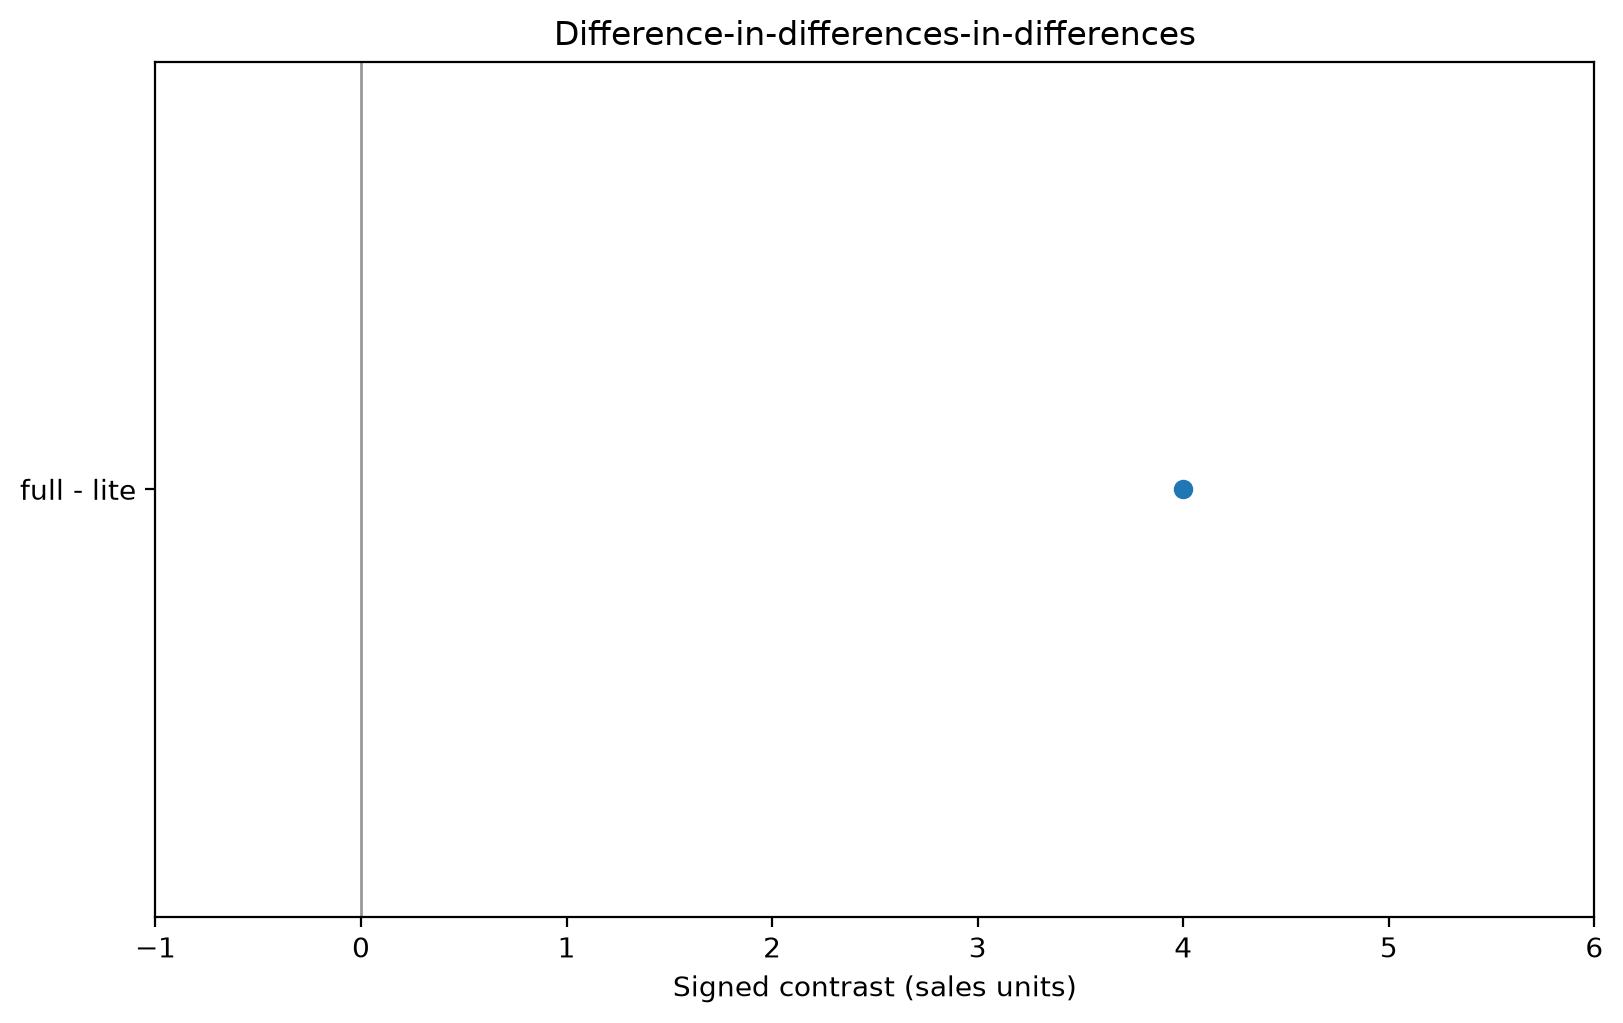

In [5]:
full_versus_lite.plot(
    outcome_units="sales units",
    figsize=(FIG_WIDTH, FIG_HEIGHT),
);

**Caption:** Signed contrast of two ordinary difference-in-differences, in sales units. The mark is the full-sample contrast. The line at zero is a reference, not an estimate. This ordinary-least-squares fit has one draw, so the figure has no interval.

## What has to be true

Without the difference in refurbishment, the treated-minus-control sales trend would have been the same in the full tier and the lite tier.

A shared shock of 2 extra sales units on treated stores in both the lite and full tiers moves those ordinary difference-in-differences from 5 and 9 to 7 and 11. Full minus lite stays 4. A shock of 2 that hits only the full tier's treated stores moves that tier from 9 to 11 and leaves lite at 5, so full minus lite becomes 6. The 4 depends on the shared shock cancelling. It is not the ordinary parallel-trends statement repeated twice, and it is not a claim about stores that adopt at different times.

In [6]:
def with_treated_shock(frame, tiers, extra):
    shocked = frame.copy()
    mask = (
        shocked["tier"].isin(tiers)
        & (shocked["group"] == 1)
        & (shocked["post_treatment"] == 1)
    )
    shocked.loc[mask, "y"] = shocked.loc[mask, "y"] + extra
    return shocked


def shock_estimates(frame):
    table = (
        cp.DifferenceInDifferencesInDifferences(
            frame,
            FORMULA,
            "t",
            "group",
            level_variable_name="tier",
            contrasts=[("full", "lite")],
            model=MODEL,
        )
        .fit()
        .table()
        .set_index("label")
    )
    return {
        "lite": float(table.loc["lite", "estimate"]),
        "full": float(table.loc["full", "estimate"]),
        "full minus lite": float(table.loc["full - lite", "estimate"]),
    }


shared = with_treated_shock(sales, ["lite", "full"], 2.0)
full_only = with_treated_shock(sales, ["full"], 2.0)
pd.DataFrame(
    [
        shock_estimates(shared),
        shock_estimates(full_only),
    ],
    index=["shared shock of 2", "full-only shock of 2"],
)

,lite,full,full minus lite
shared shock of 2,7.0,11.0,4.0
full-only shock of 2,5.0,11.0,6.0


## Where the interval comes from

The interval is the spread of full-minus-lite inside each posterior draw, or inside each bootstrap replicate that keeps a store's periods and tiers together. Subtracting the two tiers' standard errors is the attractive wrong interval. If those two standard errors are equal, that subtraction says the comparison is exact.

The three pairs below are a separate arithmetic warning. They are not draws from this sales fit, and they are not the retailer's ordinary differences 2, 5, and 9 or the contrasts 3, 7, and 4. Each pair has the same standard error. Subtracting those standard errors gives 0, while the paired differences stay 2, 6, and 10. That spread is positive. The sales figure stays the point. Its interval, when a fit has draws or a bootstrap, has to be this kind of spread.

In [7]:
series = pd.DataFrame(
    {"series 1": [7.0, 9.0, 11.0], "series 2": [5.0, 3.0, 1.0]},
    index=["(7, 5)", "(9, 3)", "(11, 1)"],
)
warning = cp.DifferenceInDifferencesInDifferences.summarize_paired_effects(
    {"series 1": series["series 1"], "series 2": series["series 2"]},
    [("series 1", "series 2")],
)
standard_error = series.std(ddof=1)
pd.DataFrame(
    {
        "paired difference": warning.contrast_draws.iloc[:, 0].to_numpy(),
        "series 1 standard error": standard_error["series 1"],
        "series 2 standard error": standard_error["series 2"],
        "subtracted standard errors": (
            standard_error["series 1"] - standard_error["series 2"]
        ),
    },
    index=series.index,
)

,paired difference,series 1 standard error,series 2 standard error,subtracted standard errors
"(7, 5)",2.0,2.0,2.0,0.0
"(9, 3)",6.0,2.0,2.0,0.0
"(11, 1)",10.0,2.0,2.0,0.0


## What 4 sales units does not say

4 sales units is how much larger the treated-versus-control change was for full refurbishment than for lite, if the treated-minus-control trend would have matched across those tiers without the tier difference. Equal standard errors do not make that comparison exact. It does not say that full refurbishment caused 4 extra sales when that cross-tier assumption fails. It does not say the untouched tier is a third treatment. It does not say the comparison is an estimate for stores that adopt at different times.